# **Sesión 4:** Procesamiento de imagenes y extracción de características

## **Librerías**

In [4]:
import cv2
print("OpenCV should be 4.8.x Current version:", cv2.__version__)
from typing import List
import numpy as np
# import imageio --- IGNORE IF DEPRECATED---
import imageio.v3 as imageio
import copy
import os
import glob
import matplotlib.pyplot as plt

OpenCV should be 4.8.x Current version: 4.8.0


## **Apartado B:** Detección de lineas rectas
El objetivo de este apartado es la detección de líneas y bordes en las imágenes de la carpeta `data/partA-B`.
1. **Tarea B.1.** Aplique `cv2.Canny()` a las imágenes de trabajo ajustando los hiperparámetros.
3. **Tarea B.2.** Implemente la función `draw_lines()` para pintar las líneas sobre las imágenes.
4. **Tarea B.3.** Aplique Hough con `cv2.HoughLinesP()` a las imágenes de trabajo para extraer líneas y afine los hiperparámetros.
5. **Pregunta B.1.** Repita el procedimiento para extraer las líneas de las dos imágenes restantes.

### **NOTA**
Podéis usar el mismo formato de guardado de resultados y nomenclatura que en en las práctica 3 o hacer uso de la funcion `show_image()` del Lab 1. Usad las herramientas con las que os sintáis más cómodos

In [5]:
def load_images(filenames: List) -> List:
    return [cv2.imread(filename) for filename in filenames]

In [18]:
def show_image(img: np.array, img_name: str = "Image"):
    cv2.imshow(img_name,img)
    cv2.waitKey(3000)
    cv2.destroyAllWindows()

# TODO Complete the method, use every argument
def write_image(output_folder: str, img_name: str, img: np.array):
    img_path = os.path.join(output_folder,img_name)
    cv2.imwrite(img_path,img)

### **Tarea B.1.** Aplique `cv2.Canny()` a las imágenes de trabajo ajustando los hiperparámetros

In [19]:
# TODO Apply canny to the images, play with the thresholds to get a good result

edge_imgs = []  # to store the canny edge images for later Hough transform

#Load images
imgs_path = []
from pathlib import Path
carpeta = Path('../data/partA-B')
for archivo in carpeta.iterdir():
    if archivo.is_file():
        imgs_path.append(f"../data/partA-B/{archivo.name}")
imgs = load_images(imgs_path)

# 1st image

# Hyperparameters 
low_threshold = 100 #100
high_threshold = 200 #200

# get the first image 
img1 = imgs[0]
# Convert to grayscale
gray_img1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)

# Apply Canny edge detection
edge_img1 = cv2.Canny(gray_img1, low_threshold, high_threshold)

# Store the edge image for later Hough transform
edge_imgs.append(edge_img1)

# 2nd image 
# get the second image
img2 = imgs[1]

# Convert to grayscale
gray_img2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)

# Apply Canny edge detection
edge_img2 = cv2.Canny(gray_img2, low_threshold, high_threshold)

# Store the edge image for later Hough transform
edge_imgs.append(edge_img2)

for img in edge_imgs:
    show_image(img)


### **Tarea B.2.** Implemente `draw_lines()` para pintar las lineas sobre cada imagen

In [21]:
# TODO Draw the lines on the images. A line is a tuple of 4 integers (x1, y1, x2, y2) where (x1, y1) and (x2, y2) are the coordinates of the two points of the line.
def draw_lines(img, lines, color, thickness):
    cv2.line(img,(lines[0],lines[1]),(lines[2],lines[3]),color,thickness)


### **Tarea B.3.** Aplique Hough con `cv2.HoughLinesP()` a las imágenes de trabajo para extraer líneas y afine los hiperparámetros

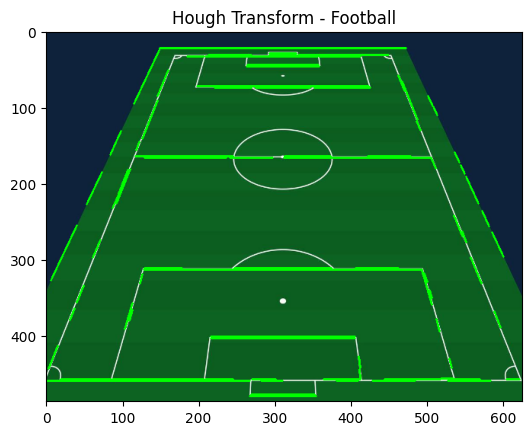

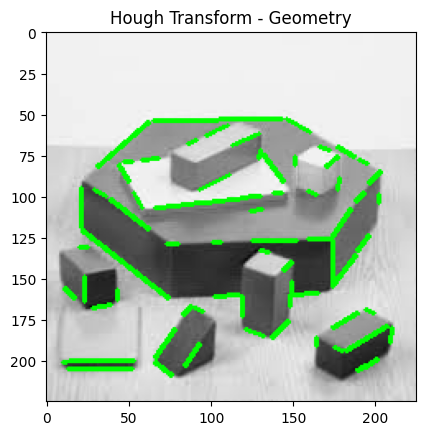

In [ ]:
# TODO Apply the hough transform to the images, play with the parameters to get a good result

# 1st image

# Define the hough transform parameters
rho = 1
theta = np.pi/180
threshold = 50
min_line_length = 50
max_line_gap = 10

# Get the edge image
edges = edge_imgs.copy()

# Apply the hough transform
lines = cv2.HoughLinesP(edges[0],rho,theta,threshold,min_line_length,max_line_gap)
img1_copy = img1.copy()
# Draw the lines on the image (on the original image, make sure to get a copy, as draw_lines modifies the image)
for line in lines:
    draw_lines(img1_copy,line[0],color=(0, 255, 0), thickness=2)

# Show the image or save it as you like
plt.imshow(cv2.cvtColor(img1_copy, cv2.COLOR_BGR2RGB))
plt.title('Hough Transform - Football')
plt.show()

# 2nd image
threshold = 10
min_line_length = 10
max_line_gap = 5
# Apply the hough transform
lines = cv2.HoughLinesP(edges[1],rho,theta,threshold,min_line_length,max_line_gap)
img2_copy = img2.copy()
# Draw the lines on the image (on the original image, make sure to get a copy, as draw_lines modifies the image)
for line in lines:
    draw_lines(img2_copy,line[0],color=(0, 255, 0), thickness=2)

# Show the image or save it as you like
plt.imshow(cv2.cvtColor(img2_copy, cv2.COLOR_BGR2RGB))
plt.title('Hough Transform - Geometry')
plt.show()

### **Pregunta B.1.** Repita el procedimiento para extraer las líneas de las dos imágenes restantes

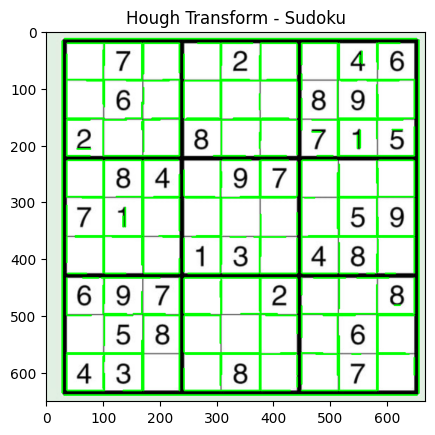

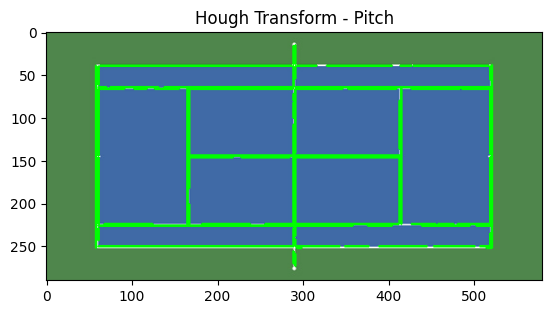

In [29]:
# TODO Homework

#Aplicamos Canny y Hough a las otras dos imágenes

edge_imgs = []  # to store the canny edge images for later Hough transform

#Load images
imgs_path = []
from pathlib import Path
carpeta = Path('../data/partA-B')
for archivo in carpeta.iterdir():
    if archivo.is_file():
        imgs_path.append(f"../data/partA-B/{archivo.name}")
imgs = load_images(imgs_path)

# 3rd image

# Hyperparameters 
low_threshold = 100
high_threshold = 200

# get the third image 
img3 = imgs[2]
# Convert to grayscale
gray_img3 = cv2.cvtColor(img3, cv2.COLOR_BGR2GRAY)

# Apply Canny edge detection
edge_img3 = cv2.Canny(gray_img3, low_threshold, high_threshold)

# Store the edge image for later Hough transform
edge_imgs.append(edge_img3)

# 4th image 
# get the fourth image
img4 = imgs[3]

# Convert to grayscale
gray_img4 = cv2.cvtColor(img4, cv2.COLOR_BGR2GRAY)

# Apply Canny edge detection
edge_img4 = cv2.Canny(gray_img4, low_threshold, high_threshold)

# Store the edge image for later Hough transform
edge_imgs.append(edge_img4)

for i in range(2,len(imgs)):
    gray_img = cv2.cvtColor(imgs[i], cv2.COLOR_BGR2GRAY)
    edge_imgs.append(cv2.Canny(gray_img, low_threshold, high_threshold))

#Aplicar Hough
# 3rd image

# Define the hough transform parameters
rho = 1
theta = np.pi/180
threshold = 50
min_line_length = 50
max_line_gap = 10

# Get the edge image
edges = edge_imgs.copy()

# Apply the hough transform
lines = cv2.HoughLinesP(edges[2],rho,theta,threshold,min_line_length,max_line_gap)
img3_copy = img3.copy()
# Draw the lines on the image (on the original image, make sure to get a copy, as draw_lines modifies the image)
for line in lines:
    draw_lines(img3_copy,line[0],color=(0, 255, 0), thickness=2)

# Show the image or save it as you like
plt.imshow(cv2.cvtColor(img3_copy, cv2.COLOR_BGR2RGB))
plt.title('Hough Transform - Sudoku')
plt.show()

# 4th image
threshold = 10
min_line_length = 10
max_line_gap = 5
# Apply the hough transform
lines = cv2.HoughLinesP(edges[3],rho,theta,threshold,min_line_length,max_line_gap)
img4_copy = img4.copy()
# Draw the lines on the image (on the original image, make sure to get a copy, as draw_lines modifies the image)
for line in lines:
    draw_lines(img4_copy,line[0],color=(0, 255, 0), thickness=2)

# Show the image or save it as you like
plt.imshow(cv2.cvtColor(img4_copy, cv2.COLOR_BGR2RGB))
plt.title('Hough Transform - Pitch')
plt.show()
